### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, plot_predict

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2008-07-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2015-07-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [10]:
data.shape

(31972, 14)

In [11]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preperation for Prediction

In [12]:
DMFEM = data.copy()
DMFEM = DMFEM[DMFEM['category']=='meat, fish and eggs']
DMFEM.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
72,1/15/2008,Shan (South),Taunggyi,Hsihseng,"meat, fish and eggs",Meat (beef),beef,NaN,KG,actual,Retail,MMK,2424.24,1.3619
73,1/15/2008,Shan (South),Taunggyi,Hsihseng,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,2909.09,1.6343
74,1/15/2008,Shan (South),Taunggyi,Hsihseng,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429


In [13]:
DMFEM = DMFEM[['date', 'price']]
DMFEM['date'] = pd.to_datetime(DMFEM['date'])
mask = (DMFEM['date']>=obv_st_date) & (DMFEM['date']<=obv_end_date)
DMFEM = DMFEM.loc[mask]
DMFEM = DMFEM.set_index('date')
DMFEM.head()

,price
date,
2008-07-15,2424.24
2008-07-15,4848.48
2008-07-15,3636.36
2008-07-15,3636.36
2008-07-15,3636.36


In [14]:
DMFEM = DMFEM.resample('MS').mean()
DMFEM.head()

,price
date,
2008-07-01,3636.360000
2008-08-01,3303.028333
2008-09-01,3505.048333
2008-10-01,3404.038333
2008-11-01,3383.835000


In [15]:
price = DMFEM['price']
date = DMFEM.index

##### Normalization data

In [16]:
scaler = MinMaxScaler()

In [17]:
DMFEM = scaler.fit_transform(DMFEM)
DMFEM = pd.DataFrame(DMFEM)
DMFEM.head()

,0
0,1.000000
1,0.857898
2,0.944021
3,0.900959
4,0.892346


In [18]:
DMFEM['date']=date
DMFEM = DMFEM.set_index('date')
DMFEM.columns=['price']
DMFEM.head()

,price
date,
2008-07-01,1.000000
2008-08-01,0.857898
2008-09-01,0.944021
2008-10-01,0.900959
2008-11-01,0.892346


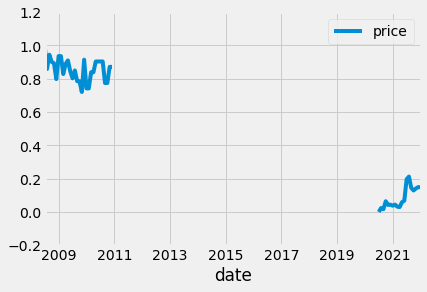

In [19]:
DMFEM.plot(grid=True)
plt.show()

There is too many missing data. We need to fill

#####  Filling data with linear interpolation

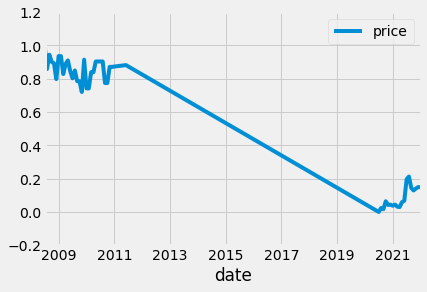

In [20]:
DMFEM = DMFEM.interpolate(method='linear')
DMFEM.plot(grid=True)
plt.show()

There is negative trend.

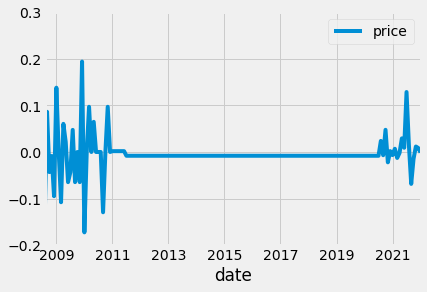

In [21]:
DMFEM_diff1 = DMFEM.diff(1).dropna()
DMFEM_diff1.plot(grid=True)
plt.show()

##### Checking Random Walk

In [22]:
RW_DMFEM = adfuller(DMFEM_diff1)
RW_DMFEM[1] # print P-value. If p-value<5%, reject null hypothesis

0.29458673723901996

<span style="color:red">What is influenced for this price?</span>

##### Plotting ACF and PACF

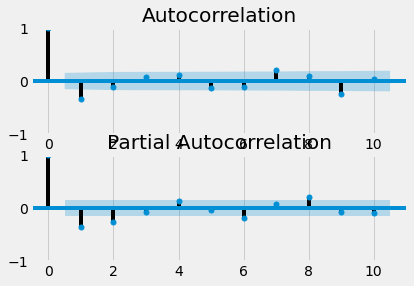

In [23]:
fig, axes=plt.subplots(2,1)
plot_acf(DMFEM_diff1, lags=10, ax=axes[0])
plot_pacf(DMFEM_diff1, lags=10, ax=axes[1])
plt.show()

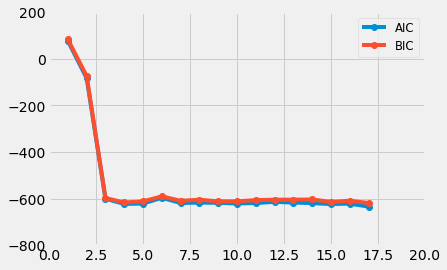

In [24]:
AIC, BIC = AIC_BIC_withOrderRange(DMFEM,p=3, d=2, q=3)
# 0:(0,0,0), 1:(0,0,1), 2:(0,0,2), 3:(0,1,0), 4:(0,1,1), 5:(0,1,2), 
# 6:(1,0,0), 7:(1,0,1), 8:(1,0,2), 9:(1,1,0), 10:(1,1,1), 11:(1,1,2), 
# 12:(2,0,0), 13:(2,0,1), 14:(2,0,2), 15:(2,1,0), 16:(2,1,1), 17:(2,1,2)

In [25]:
AIC, BIC

(array([ 286.72123009,   76.18191794,  -83.72828422, -600.37154121,
        -622.6493968 , -620.99456475, -596.35934364, -618.62513993,
        -616.97207973, -617.8007918 , -620.82135468, -618.67730791,
        -613.78438937, -616.79810183, -619.04643657, -623.24038249,
        -621.25129222, -634.07974589]),
 array([ 289.81498029,   82.36941834,  -74.44703362, -597.28394488,
        -616.47420413, -611.73177574, -590.17184324, -609.34388932,
        -604.59707893, -611.62559913, -611.55856568, -606.32692257,
        -604.50313877, -604.42310102, -603.57768557, -613.97759349,
        -608.90090688, -618.64176421]))

We will run again 2:(0,0,2), 3:(0,1,0), 4:(0,1,1), 5:(0,1,2), 7:(1,0,1), 8:(1,0,2), 9:(1,1,0), 10:(1,1,1), 11:(1,1,2), 
12:(2,0,0), 13:(2,0,1), 15:(2,1,0), 16:(2,1,1), 17:(2,1,2)

In [26]:
mod_orders = [
    (0,0,2), 
    (0,1,0), 
    (0,1,1), 
    (0,1,2), 
    (1,0,1), 
    (1,0,2), 
    (1,1,0), 
    (1,1,1), 
    (1,1,2), 
    (2,0,0),
    (2,0,1),
    (2,1,0), 
    (2,1,1), 
    (2,1,2)
]

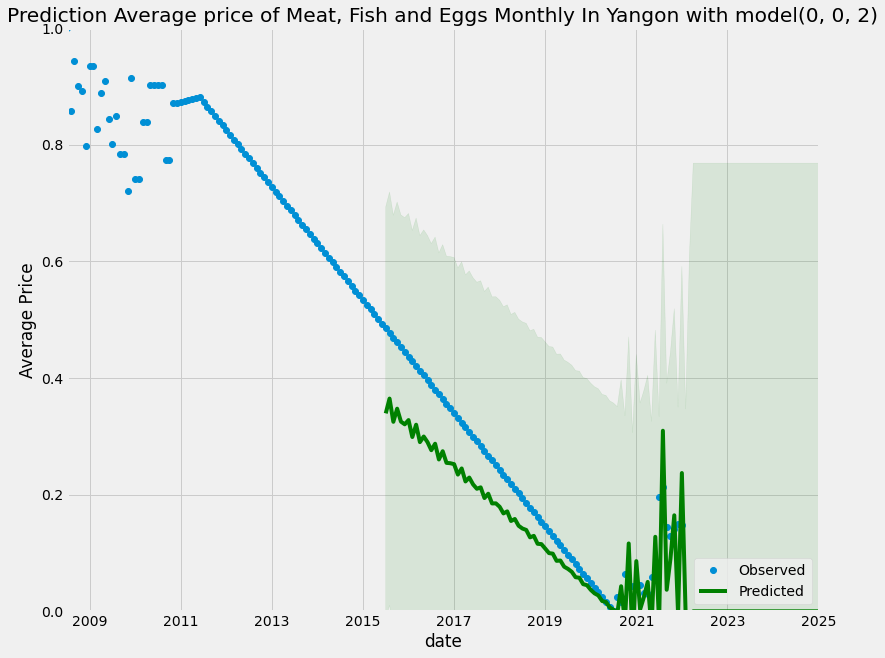

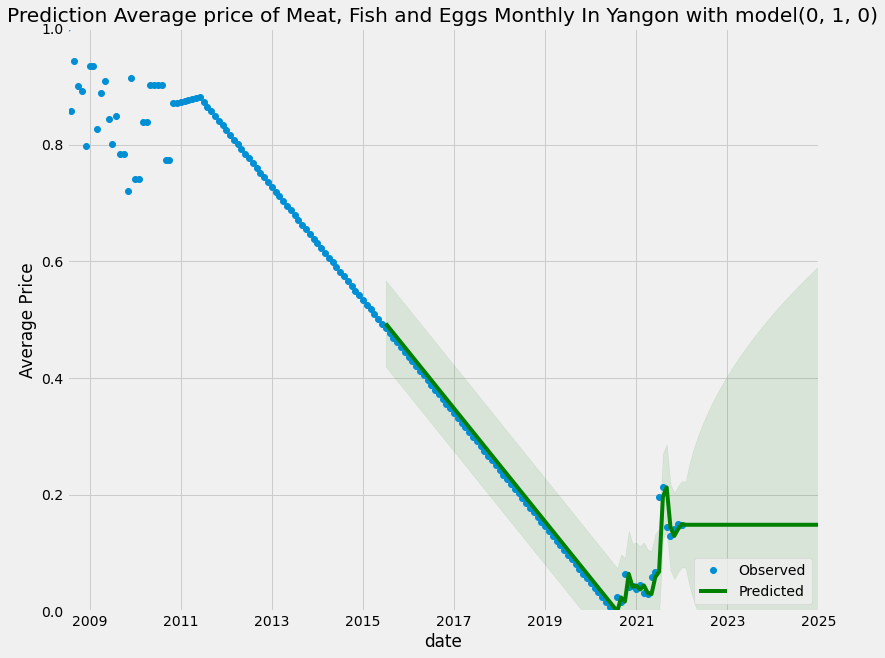

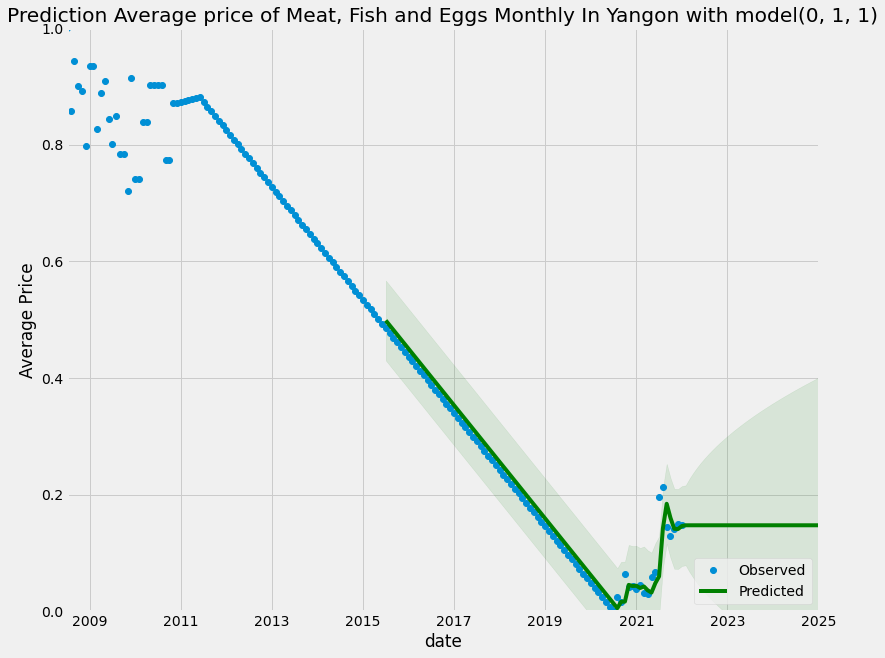

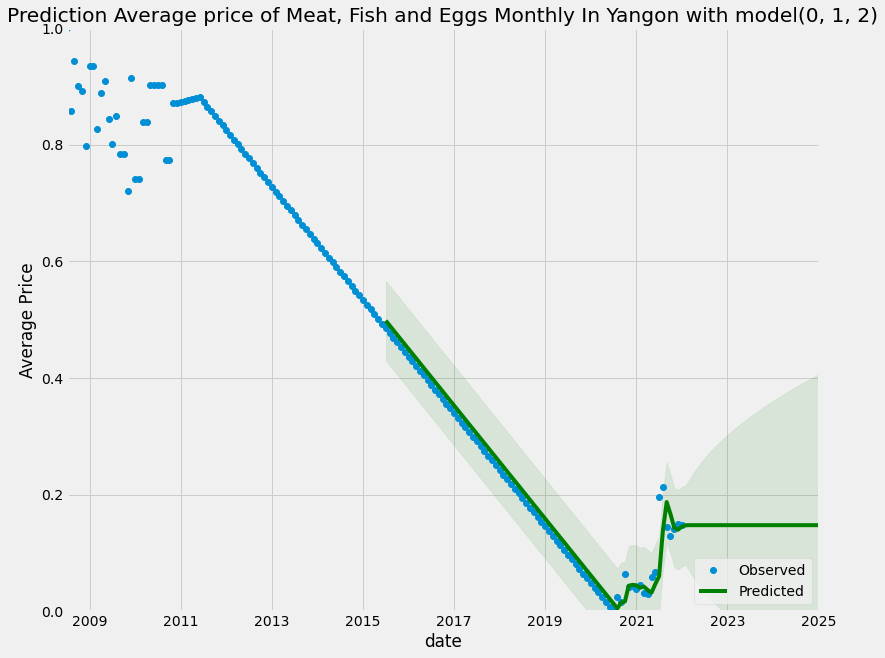

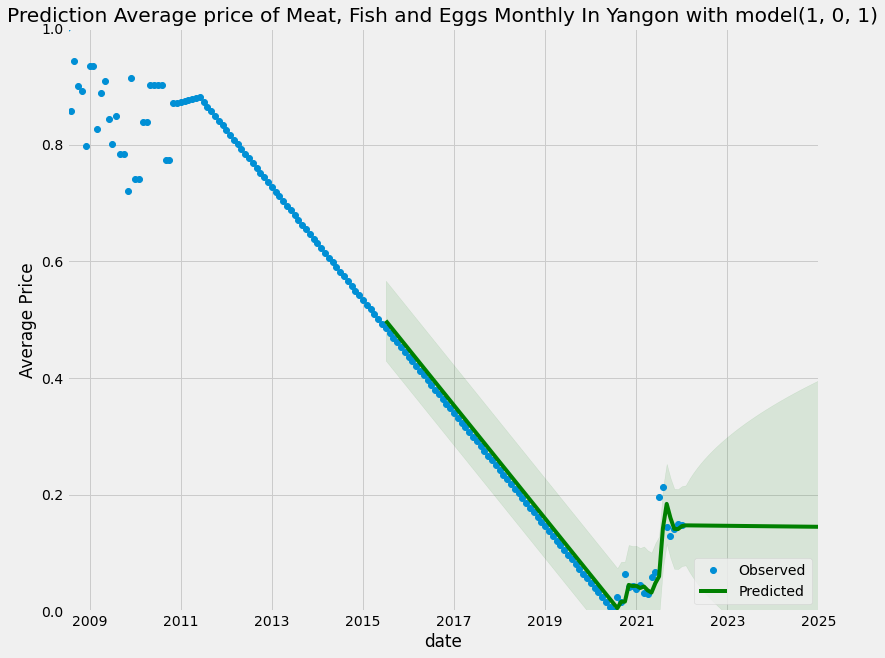

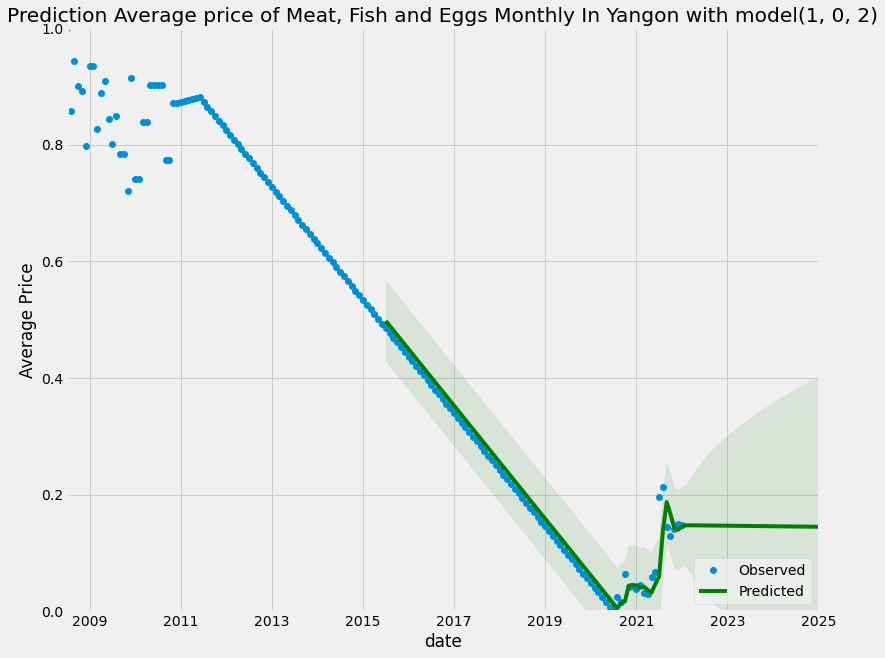

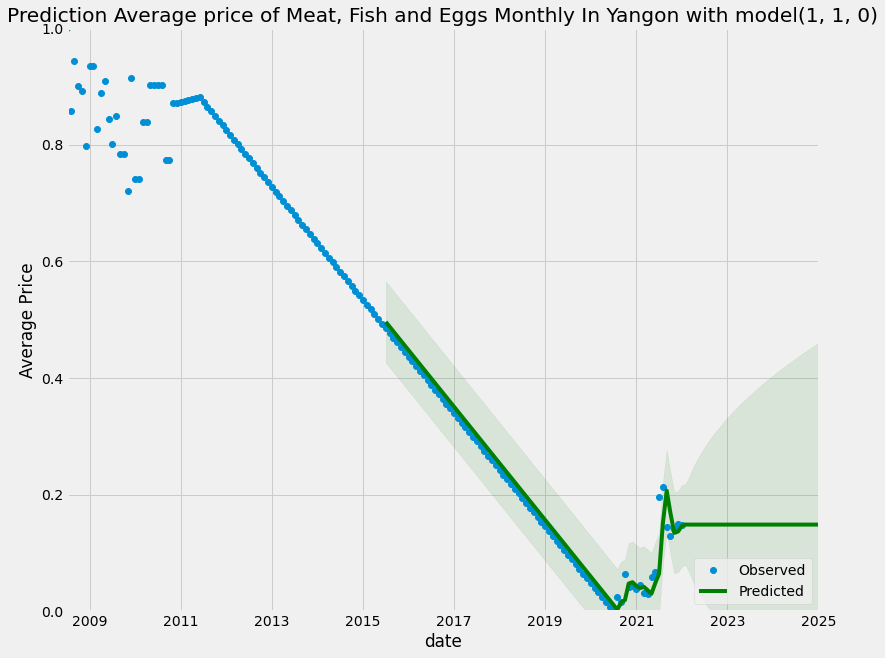

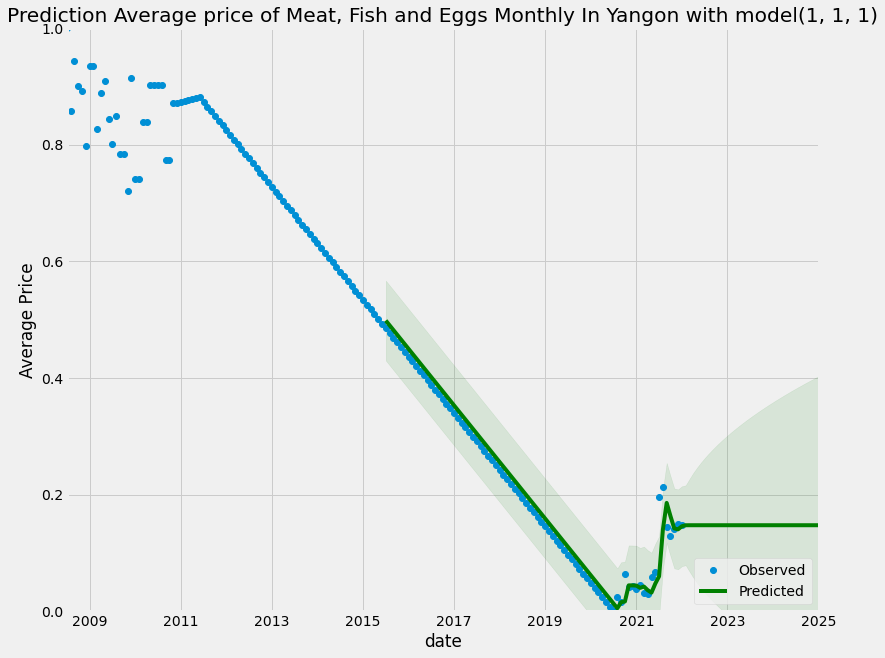

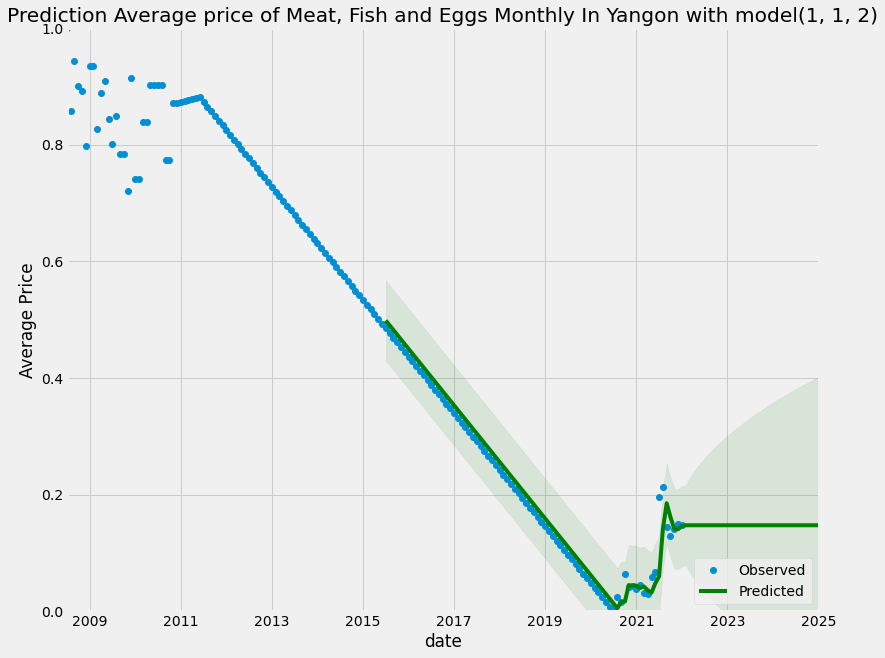

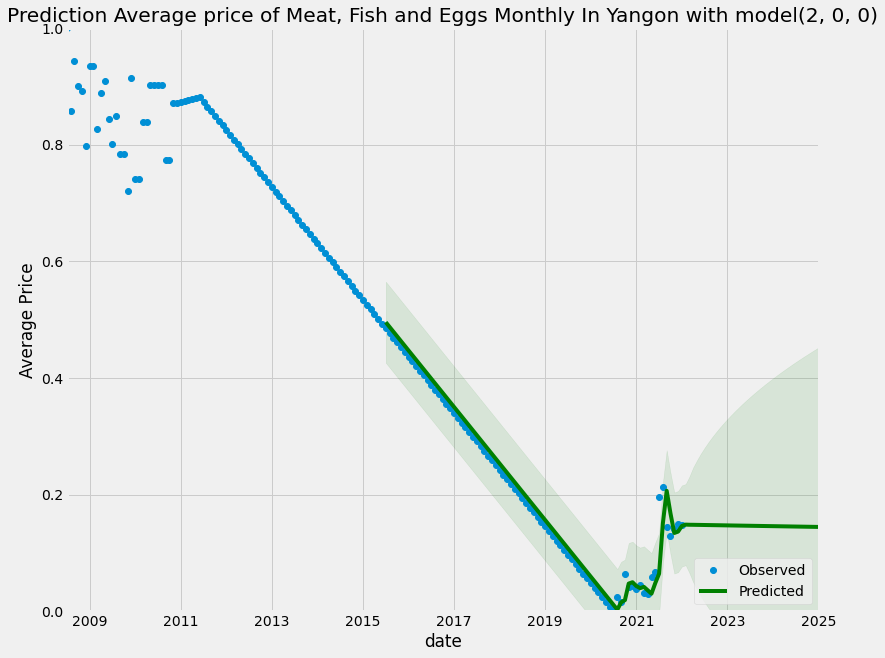

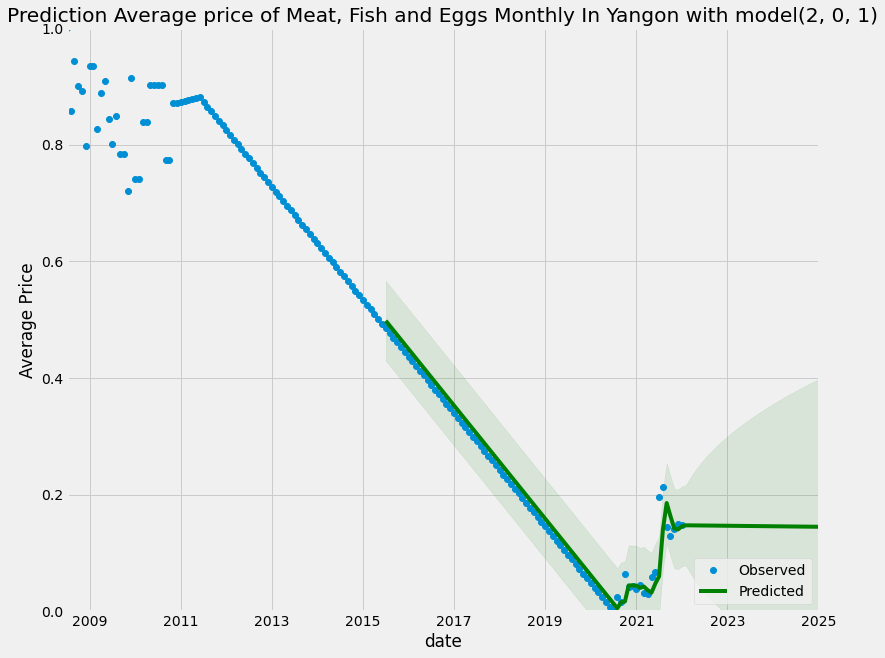

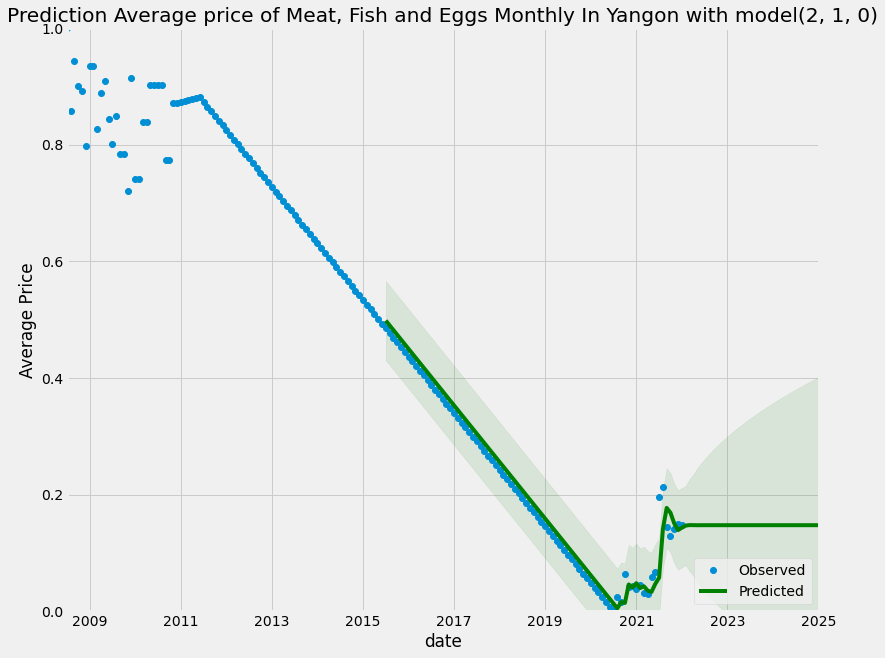

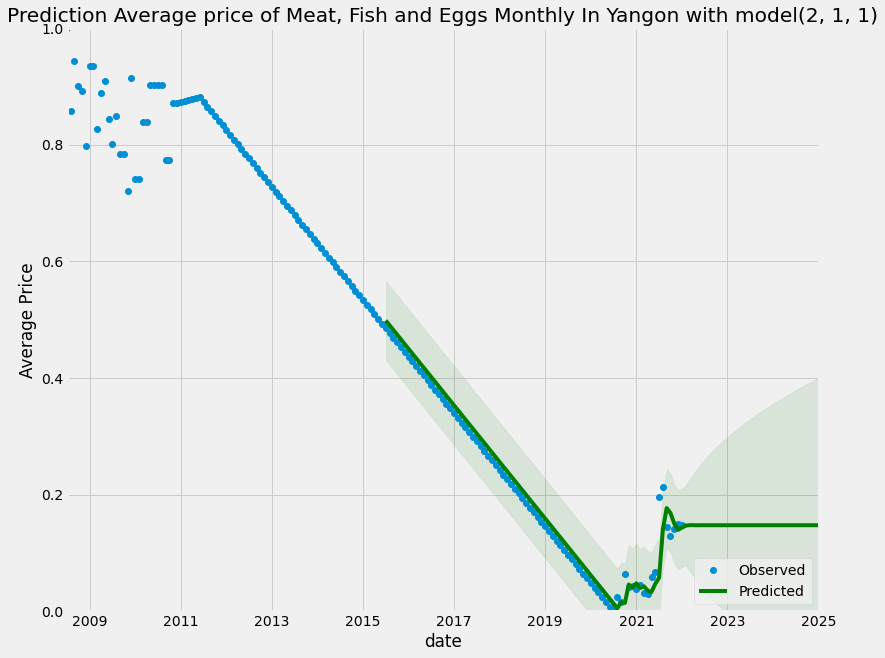

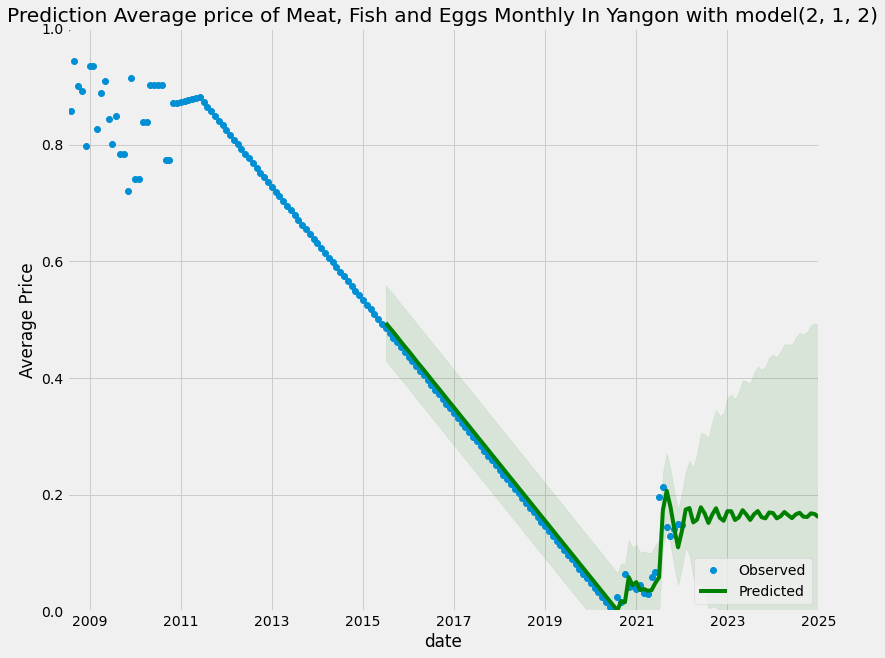

In [27]:
DMFEM_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DMFEM, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Meat, Fish and Eggs Monthly In Yangon with model'+str(order), xlabel='Date', ylabel='Average Price')
    DMFEM_models.append(model)

Now we choose (2,1,2)

In [28]:
DMFEM_model = DMFEM_models[13]

In [29]:
DMFEM_pred_normalized = DMFEM_model.predict(pred_st_date, pred_end_date)
DMFEM_pred_normalized

2015-07-01    0.494486
2015-08-01    0.486424
2015-09-01    0.478845
2015-10-01    0.470712
2015-11-01    0.462203
                ...   
2024-09-01    0.162287
2024-10-01    0.161702
2024-11-01    0.167999
2024-12-01    0.166705
2025-01-01    0.161315
Freq: MS, Name: predicted_mean, Length: 115, dtype: float64

We need to un-normalized the predicted value to get actual price

In [30]:
pred_date = DMFEM_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2015-07-01', '2015-08-01', '2015-09-01', '2015-10-01',
               '2015-11-01', '2015-12-01', '2016-01-01', '2016-02-01',
               '2016-03-01', '2016-04-01',
               ...
               '2024-03-01', '2024-04-01', '2024-05-01', '2024-06-01',
               '2024-07-01', '2024-08-01', '2024-09-01', '2024-10-01',
               '2024-11-01', '2024-12-01'],
              dtype='datetime64[ns]', length=114, freq='MS')

In [31]:
DMFEM_pred_normalized_df = pd.DataFrame(DMFEM_pred_normalized)
DMFEM_pred_normalized_df = DMFEM_pred_normalized_df[:-1] # the last index doesn't need
DMFEM_pred_normalized_df

,predicted_mean
2015-07-01,0.494486
2015-08-01,0.486424
2015-09-01,0.478845
2015-10-01,0.470712
2015-11-01,0.462203
...,...
2024-08-01,0.168977
2024-09-01,0.162287
2024-10-01,0.161702
2024-11-01,0.167999


##### Un-normalization

In [32]:
DMFEM_pred_act = scaler.inverse_transform(DMFEM_pred_normalized_df)
DMFEM_pred_act_df = pd.DataFrame(DMFEM_pred_act)
DMFEM_pred_act_df['date'] = pred_date
DMFEM_pred_act_df.columns = ['Predicted Price', 'date']
DMFEM_pred_act_df.head()

,Predicted Price,date
0,2450.567249,2015-07-01
1,2431.657657,2015-08-01
2,2413.877928,2015-09-01
3,2394.800423,2015-10-01
4,2374.842054,2015-11-01


In [33]:
DMFEM_pred_act_df.set_index('date',  inplace=True)

In [34]:
DMFEM_pred_act_df['2020-09-01':'2022-09-01']

,Predicted Price
date,
2020-09-01,1331.267184
2020-10-01,1327.183345
2020-11-01,1428.012317
2020-12-01,1395.782012
2021-01-01,1408.055217
2021-02-01,1375.978828
2021-03-01,1380.400295
2021-04-01,1373.397873
2021-05-01,1375.185574
